# 01 — EDA et manifest du dataset dentaire

**Auteur :** _ton nom_  |  **Dataset :** Kaggle Oral Image Dataset (6 classes)

## Pourquoi ce notebook existe
Observation de départ : le dataset contient **déjà des copies modifiées des mêmes photos** (luminosité, etc.) et certaines images sont **deux photos collées** (un côté sain, un côté problématique). Conséquences :

1. Si une photo et sa copie modifiée tombent l'une dans le **train** et l'autre dans le **test**, le modèle est évalué sur une image qu'il connaît déjà : **fuite de données**, scores trop optimistes. Un contrôle de doublons exacts ne les voit pas.
2. Le nombre d'images (4 375) n'est **pas** le nombre de photos indépendantes. C'est la vraie taille du dataset qu'il faut connaître.
3. Les images composites posent une question sur la validité des étiquettes.

## Ce que ce notebook produit
- Les graphiques et chiffres de l'EDA (dans `outputs/eda/`).
- Un fichier **`data/data_manifest.csv`** : une ligne par image avec sa classe, son **groupe de copies** et son **split** (train / val / test). Le notebook d'entraînement (`PR1_notebook_ResNet50`) le lit : toute l'équipe évalue sur **le même test**.
- `data/class_names.json` (ordre des classes) et `data/composites_manual.csv` (composites étiquetés à la main).
- Une copie de tout cela sur **Google Drive** (`MyDrive/dentalguide/eda_v2/`), car Colab efface ses fichiers à la fin de la session.
- Un Excel de synthèse (`outputs/eda/eda_summary.xlsx`) pour les slides.

## Comment l'utiliser
1. Colab : **Exécution > Modifier le type d'exécution > GPU T4** (accélère la section 3.6).
2. Exécute dans l'ordre et accepte l'accès à Google Drive. Deux paramètres sont **réglés en regardant les images** (✋ marqués) : le seuil de copies (section 3.6) et le seuil d'images composites (section 3.4).
3. Les cellules ✍️ sont à écrire **avec tes mots** : c'est ce qui est noté et ce que tu défendras à l'oral.

## Modifications du 17/11
- Les images composites sont maintenant **retirées** (c'était la décision écrite en 3.4b, mais le code les gardait).
- Les composites sont enregistrés par **nom de fichier + empreinte MD5**, plus seulement par numéro de ligne.
- Noms de classes harmonisés (`Caries`, `Mouth Ulcer`, `Tooth Discoloration`).
- Résultats copiés sur Google Drive.
- Ajouts : biais de résolution (3.5b), graphique des photos indépendantes, estimation chiffrée de la fuite (4.2).

> Ce code a été généré avec l'aide de Claude. Tu dois pouvoir expliquer chaque cellule sans notes. Note tes vérifications dans ton AI Use Log.

## 1. Mise en place

In [1]:
!pip -q install kagglehub

In [2]:
import io, os, hashlib, json, random, shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from tqdm.auto import tqdm
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.model_selection import StratifiedGroupKFold
import torch
from torchvision import models
from google.colab import drive

# ---------- Paramètres ----------
SEED = 42
TEST_FRACTION = 0.15          # visé : ~15 % test (le découpage par groupes donne un résultat approché)
VAL_FRACTION = 0.15           # visé : ~15 % validation
DUP_THRESHOLD = 0.14          # ✋ distance cosinus (= 1 − similarité) sous laquelle deux images sont "la même photo modifiée". 0.14 ⇔ similarité 0,86 : choix de l'équipe, à justifier avec la table de sensibilité (3.6)
SEAM_THRESHOLD = 4.0          # ✋ score au-dessus duquel on soupçonne "deux photos collées" : sert seulement à trier (3.4b)

# Nom du dossier dans le dataset -> nom de classe utilisé partout dans le projet
FOLDER_TO_LABEL = {
    "Calculus": "Calculus",
    "Hypodontia": "Hypodontia",
    "Mouth ulcer": "Mouth Ulcer",
    "Normal": "Normal",
    "caries": "Caries",
    "tooth discoloration": "Tooth Discoloration",
}
# Composites relevés à la main le 14/11 : sert à vérifier que les numéros pointent toujours sur les bonnes images
EXPECTED_COMPOSITES = {"Calculus": 77, "Tooth Discoloration": 13, "Mouth Ulcer": 3}

MANIFEST_PATH = Path("data/data_manifest.csv")
CLASSES_PATH = Path("data/class_names.json")
OUT_DIR = Path("outputs/eda")
DRIVE_DIR = Path("/content/drive/MyDrive/dentalguide/eda_v2")   # copie durable des résultats
MANIFEST_PATH.parent.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

drive.mount("/content/drive")
DRIVE_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Appareil :", DEVICE, "(un GPU accélère la section 3.6 ; sans GPU, compte ~10 min)")

Mounted at /content/drive
Appareil : cuda (un GPU accélère la section 3.6 ; sans GPU, compte ~10 min)


## 2. Les données

### 2.1 Téléchargement
Le dataset est public (CC0) : on le télécharge depuis Kaggle dans Colab. **On ne le met jamais dans GitHub** (473 Mo). Si Kaggle demande une authentification : *Kaggle > Settings > API > Create New Token*, puis dans Colab (icône 🔑 *Secrets*) ajoute `KAGGLE_USERNAME` et `KAGGLE_KEY`.

In [3]:
import kagglehub

try:
    DATA_ROOT = Path(kagglehub.dataset_download("jhirshaikh/oral-image-dataset"))
except Exception as e:
    print("Téléchargement impossible :", e)
    print("-> Mets le dataset dans Colab à la main et indique son dossier ci-dessous.")
    DATA_ROOT = Path("/content/oral-image-dataset")   # <-- à adapter si besoin

print("Dataset dans :", DATA_ROOT)

100%|██████████| 429M/429M [00:26<00:00, 16.7MB/s]

Extracting files...


Dataset dans : /root/.cache/kagglehub/datasets/jhirshaikh/oral-image-dataset/versions/1


### 2.2 Inventaire
Une ligne par image : chemin **relatif** au dossier du dataset (il change à chaque session Colab, le chemin relatif non), classe (= nom du dossier parent), largeur, hauteur.
Les lignes sont **triées** : l'ordre de lecture des dossiers n'est pas garanti, et un ordre différent donnerait un split différent. Trié = reproductible chez tout le monde.

**À vérifier :** 6 classes attendues (Calculus, Caries, Hypodontia, Mouth Ulcer, Normal, Tooth Discoloration).

In [4]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
SPLIT_FOLDERS = {"train", "test", "val", "valid", "validation"}   # dossiers de découpage, pas des classes

rows = []
for p in DATA_ROOT.rglob("*"):
    if p.suffix.lower() in IMG_EXT:
        folder = p.parent.name
        if folder.lower() in SPLIT_FOLDERS:
            continue
        if folder not in FOLDER_TO_LABEL:
            raise ValueError(f"Dossier inattendu : {folder!r}. Ajoute-le dans FOLDER_TO_LABEL.")
        with Image.open(p) as im:
            w, h = im.size
        rows.append({"rel_path": p.relative_to(DATA_ROOT).as_posix(), "label": FOLDER_TO_LABEL[folder], "width": w, "height": h})

df = pd.DataFrame(rows).sort_values("rel_path").reset_index(drop=True)
assert len(df) > 0, "Aucune image trouvée : vérifie DATA_ROOT"
df["path"] = df.rel_path.map(lambda r: str(DATA_ROOT / r))
print(f"{len(df)} images, {df.label.nunique()} classes")
print(df.label.value_counts())
if df.label.nunique() != 6:
    print("ATTENTION : on attendait 6 classes. Regarde les noms ci-dessus et la structure des dossiers.")

4375 images, 6 classes
label
Calculus               1296
Hypodontia             1251
Tooth Discoloration    1058
Normal                  286
Mouth Ulcer             265
Caries                  219
Name: count, dtype: int64


## 3. EDA

### 3.1 Combien d'images par classe ?

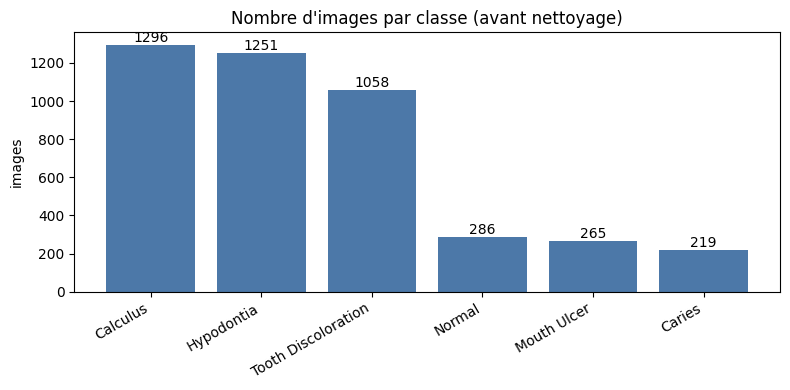

Rapport plus grande / plus petite classe : 5.9x


In [5]:
counts = df.label.value_counts()
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(counts.index, counts.values, color="#4C78A8")
ax.bar_label(bars)
ax.set_title("Nombre d'images par classe (avant nettoyage)"); ax.set_ylabel("images")
plt.xticks(rotation=30, ha="right")
fig.tight_layout(); fig.savefig(OUT_DIR / "eda_class_counts.png", dpi=150); plt.show()
print(f"Rapport plus grande / plus petite classe : {counts.max() / counts.min():.1f}x")

### 3.2 Regarder **chaque** classe
5 images au hasard par classe. Regarde en particulier : les copies plus claires ou plus sombres d'une même photo, les images à deux photos, les étiquettes qui te semblent douteuses. **Relance la cellule plusieurs fois** pour voir d'autres images (change `GRID_SEED`).

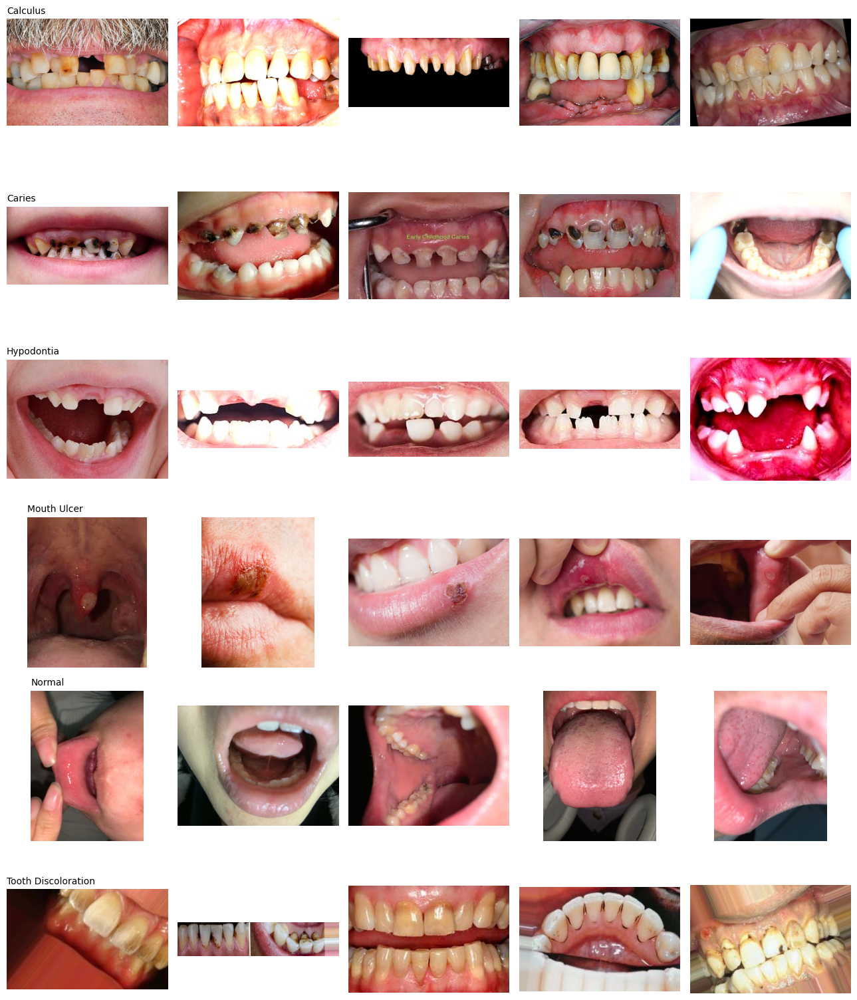

In [6]:
GRID_SEED = 0
classes_sorted = sorted(df.label.unique())
n_show = 5
fig, axes = plt.subplots(len(classes_sorted), n_show, figsize=(2.6 * n_show, 2.6 * len(classes_sorted)))
rng = np.random.RandomState(GRID_SEED)
for r, cls in enumerate(classes_sorted):
    paths = df[df.label == cls].path.tolist()
    for c, p in enumerate(rng.choice(paths, size=min(n_show, len(paths)), replace=False)):
        axes[r, c].imshow(Image.open(p).convert("RGB")); axes[r, c].axis("off")
        if c == 0:
            axes[r, c].set_title(cls, loc="left", fontsize=10)
fig.tight_layout(); fig.savefig(OUT_DIR / "eda_sample_grid.png", dpi=120); plt.show()

### 3.3 Analyse de **toutes** les images en une passe
Pour chaque image, on calcule en une seule lecture :
- l'empreinte **MD5** (doublons exacts) ;
- la **luminosité** moyenne ;
- le **score de couture** (voir 3.4) ;

Compte 2 à 5 minutes (barre de progression).

In [7]:
def seam_score(gray):
    # Une "couture" = frontière verticale nette pile au milieu (deux photos collées côte à côte).
    # Score = contraste entre colonnes voisines au centre / contraste des colonnes proches (6 à 10 colonnes de part et d'autre).
    # Autour de 1-3 : pas de couture. Très au-dessus : pic au centre, donc probable couture.
    g = np.asarray(gray.resize((128, 128)), dtype=np.float32)
    col = np.abs(np.diff(g, axis=1)).mean(axis=0)          # 127 valeurs : contraste entre colonne k et k+1
    centre = col[62:65].max()
    voisines = np.r_[col[52:58], col[67:73]].mean()
    return float(centre / (voisines + 1e-6))


records = []
for p in tqdm(df.path, desc="analyse des images"):
    data = Path(p).read_bytes()
    gray = Image.open(io.BytesIO(data)).convert("L")
    records.append({"md5": hashlib.md5(data).hexdigest(),
                    "brightness": float(np.asarray(gray, dtype=np.float32).mean()),
                    "seam": seam_score(gray)})

df = pd.concat([df, pd.DataFrame(records)], axis=1)
print("OK :", len(df), "images analysées")

analyse des images:   0%|          | 0/4375 [00:00<?, ?it/s]

OK : 4375 images analysées


### 3.4 Images à deux photos en une (images « composites »)
Heuristique : le **score de couture** compare le contraste au centre de l'image à celui des colonnes voisines : il est **bien plus élevé** quand il y a une frontière nette pile au milieu. Ce n'est qu'un indice, **pas une preuve** : regarde les images **juste au-dessus** et **juste en dessous** du seuil (là où on se trompe), puis règle `SEAM_THRESHOLD` (en haut). **Si aucun seuil ne sépare proprement les deux cas, c'est un résultat** : le score ne suffit pas, et on étiquette à la main les images suspectes (3.4b).

Juste AU-DESSUS du seuil (4.0) : sont-ce vraiment des deux photos collées ?


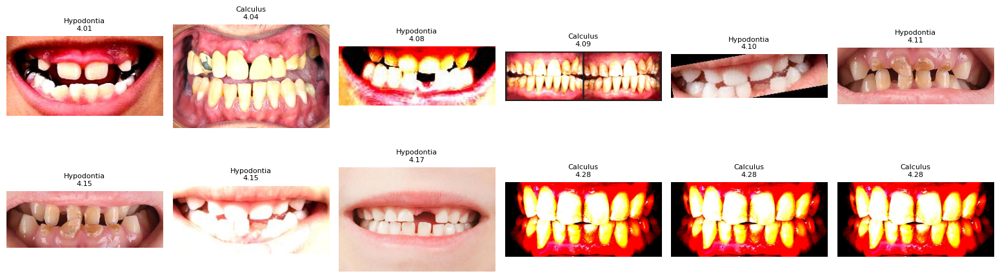

Juste EN DESSOUS du seuil (4.0) : en manque-t-on qui sont des deux photos collées ?


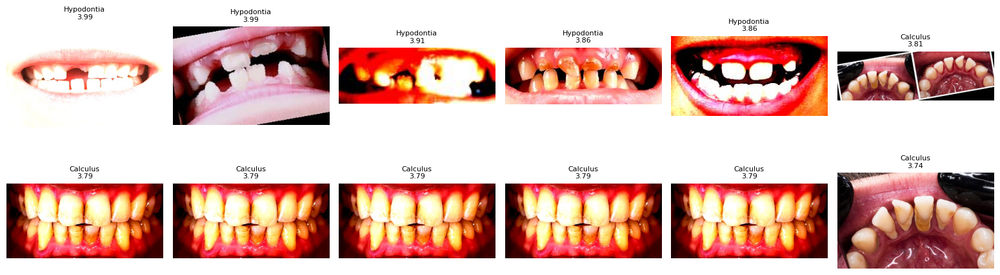

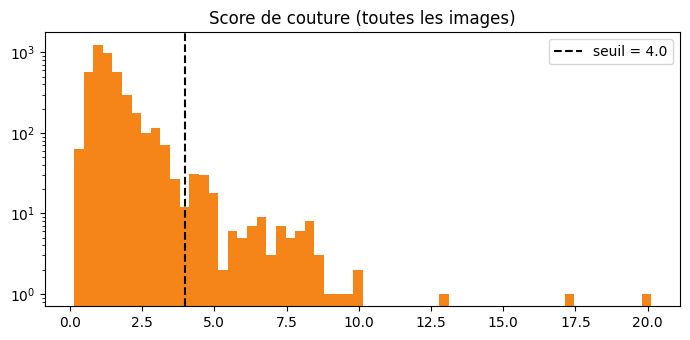

Images soupçonnées composites avec le seuil actuel : 154 sur 4375


,images_composites,part
label,,
Calculus,104,0.080
Caries,0,0.000
Hypodontia,41,0.033
Mouth Ulcer,3,0.011
Normal,0,0.000
Tooth Discoloration,6,0.006


In [8]:
def show_images(paths, titles, ncols=6, size=2.6, save=None):
    nrows = int(np.ceil(len(paths) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, size * nrows), squeeze=False)
    for ax in axes.flatten():
        ax.axis("off")
    for ax, p, t in zip(axes.flatten(), paths, titles):
        ax.imshow(Image.open(p).convert("RGB")); ax.set_title(t, fontsize=8)
    fig.tight_layout()
    if save:
        fig.savefig(OUT_DIR / save, dpi=120)
    plt.show()


# Images juste AU-DESSUS du seuil (classées composites) et juste EN DESSOUS (classées non composites) :
# c'est là qu'on se trompe le plus, donc là qu'il faut regarder pour régler SEAM_THRESHOLD.
above = df[df.seam >= SEAM_THRESHOLD].sort_values("seam").head(12)                    # les 12 plus proches du seuil, par le haut
below = df[df.seam < SEAM_THRESHOLD].sort_values("seam", ascending=False).head(12)    # les 12 plus proches du seuil, par le bas

print(f"Juste AU-DESSUS du seuil ({SEAM_THRESHOLD}) : sont-ce vraiment des deux photos collées ?")
show_images(above.path, [f"{r.label}\n{r.seam:.2f}" for r in above.itertuples()], save="eda_seam_above.png")
print(f"Juste EN DESSOUS du seuil ({SEAM_THRESHOLD}) : en manque-t-on qui sont des deux photos collées ?")
show_images(below.path, [f"{r.label}\n{r.seam:.2f}" for r in below.itertuples()], save="eda_seam_below.png")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(df.seam, bins=60, color="#F58518"); ax.axvline(SEAM_THRESHOLD, color="k", ls="--", label=f"seuil = {SEAM_THRESHOLD}")
ax.set_yscale("log"); ax.set_title("Score de couture (toutes les images)"); ax.legend()
fig.tight_layout(); plt.show()

df["composite"] = df.seam >= SEAM_THRESHOLD
comp = df.groupby("label").composite.agg(images_composites="sum", part="mean").round(3)
print(f"Images soupçonnées composites avec le seuil actuel : {int(df.composite.sum())} sur {len(df)}")
comp

### 3.4b Étiqueter les composites à la main (si le score ne sépare pas proprement)
Si en changeant `SEAM_THRESHOLD` tu trouves toujours des composites en dessous et des images normales au-dessus, **aucun seuil ne convient** : le score ne repère qu'une frontière verticale pile au centre. On l'utilise alors **seulement pour trier** : il montre d'abord les images les plus suspectes, et **c'est toi qui décides**.

1. Cellule 1 : regarde les pages (24 images par page, avec un numéro). Change `PAGE` et relance.
2. Cellule 2 : les numéros des images qui sont **vraiment** deux photos collées sont dans `COMPOSITE_IDS`. Un numéro n'est qu'une **position dans le tableau** : il change si la liste des fichiers change. On le convertit donc tout de suite en **nom de fichier + empreinte MD5**, enregistrés dans `composites_manual.csv` sur ton Drive. Dès que ce fichier existe, c'est **lui** qui fait foi, et les numéros ne servent plus.
3. Cellule 3 : la colonne `composite` utilise ces étiquettes. Cellule 4 : contrôle visuel.

Pour estimer ce que tu rates : regarde aussi quelques pages d'images **tirées au hasard** (`RANDOM_CHECK = True`).

Page 40 sur 42


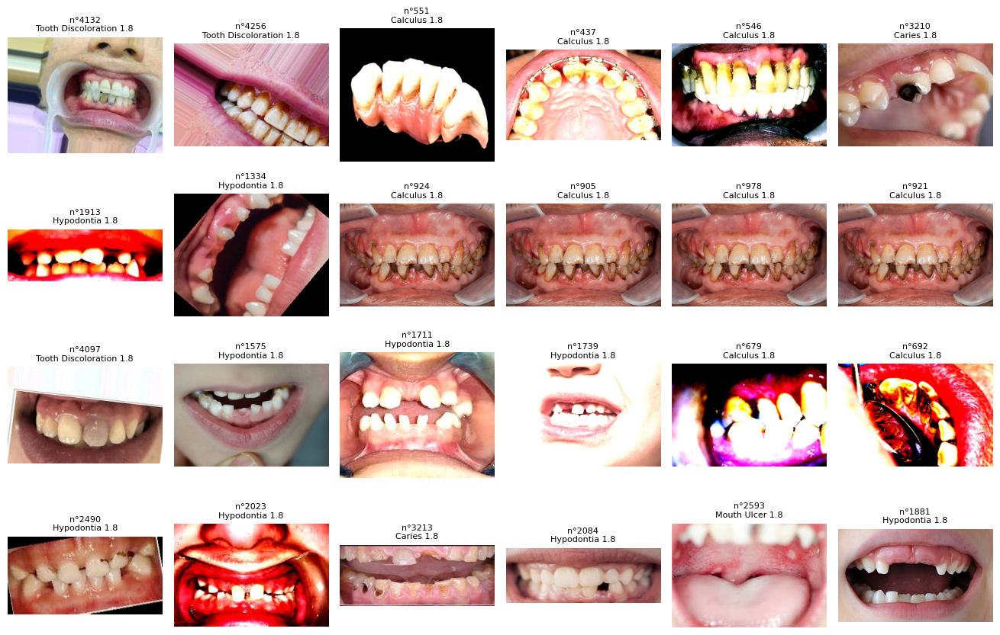

In [9]:
N_REVIEW = 1000          # nombre d'images passées en revue (les plus suspectes d'abord)
PAGE = 40                # change 0, 1, 2... pour la page suivante (24 images par page)
RANDOM_CHECK = False    # True : montre 24 images tirées au hasard HORS candidates (pour estimer ce que le score rate)

cand = df.sort_values("seam", ascending=False).head(N_REVIEW)
if RANDOM_CHECK:
    page = df.drop(cand.index).sample(24, random_state=SEED + PAGE)
else:
    page = cand.iloc[PAGE * 24:(PAGE + 1) * 24]
print(f"Page {PAGE} sur {int(np.ceil(N_REVIEW / 24))}" + (" (tirage au hasard)" if RANDOM_CHECK else ""))
show_images(page.path, [f"n°{i}\n{r.label} {r.seam:.1f}" for i, r in zip(page.index, page.itertuples())], ncols=6, size=2.2)

In [10]:
# Numéros (n°) des images qui sont VRAIMENT deux photos collées, relevés à la main le 14/11 dans les pages ci-dessus
COMPOSITE_IDS = [352, 672, 621, 285, 1101, 2800, 35, 512, 3375, 3372, 832, 176, 3437, 4016, 781, 741, 992, 461, 374, 198, 556, 940, 464, 694, 1014, 2781, 535, 3528, 855, 2807, 969, 1151, 390, 870, 701, 619, 1029, 214, 885, 910, 836, 1019, 1185, 1069, 996, 541, 357, 430, 254, 181, 381, 710, 775, 590, 516, 1045, 4084, 550, 876, 725, 566, 721, 395, 1035, 675, 750, 677, 230, 881, 3439, 1021, 531, 205, 219, 561, 4100, 861, 730, 3331, 1040, 3526, 708, 1038, 222, 879, 1260, 559, 1205, 399, 4207, 718, 3620, 4300]

COMPOSITES_FILE = DRIVE_DIR / "composites_manual.csv"
if COMPOSITES_FILE.exists():
    manual = pd.read_csv(COMPOSITES_FILE)
    print(f"{len(manual)} composites relus depuis {COMPOSITES_FILE} (les numéros ne servent plus)")
else:
    assert len(set(COMPOSITE_IDS)) == len(COMPOSITE_IDS), "Un numéro apparaît deux fois dans COMPOSITE_IDS"
    manual = df.loc[COMPOSITE_IDS, ["rel_path", "label", "md5"]]
    found = manual.label.value_counts().to_dict()
    # Si les fichiers ou leur ordre ont changé, les numéros pointent sur d'autres images : on s'arrête
    assert found == EXPECTED_COMPOSITES, f"Les numéros ne pointent plus sur les mêmes images : {found}"
    manual.to_csv(COMPOSITES_FILE, index=False)
    print(f"{len(manual)} composites convertis en nom de fichier + MD5 et enregistrés dans {COMPOSITES_FILE}")

missing = set(manual.md5) - set(df.md5)
assert not missing, f"{len(missing)} composites introuvables dans le dataset actuel"

93 composites convertis en nom de fichier + MD5 et enregistrés dans /content/drive/MyDrive/dentalguide/eda_v2/composites_manual.csv


In [11]:
# Une image est composite si son contenu (MD5) est celui d'un composite relevé : ses copies exactes le sont aussi
df["composite"] = df.md5.isin(manual.md5)
comp = df.groupby("label").composite.agg(images_composites="sum", part="mean").round(3)
print(f"Images composites retenues : {int(df.composite.sum())} sur {len(df)} (copies exactes comprises)")
comp

Images composites retenues : 93 sur 4375 (copies exactes comprises)


,images_composites,part
label,,
Calculus,77,0.059
Caries,0,0.000
Hypodontia,0,0.000
Mouth Ulcer,3,0.011
Normal,0,0.000
Tooth Discoloration,13,0.012


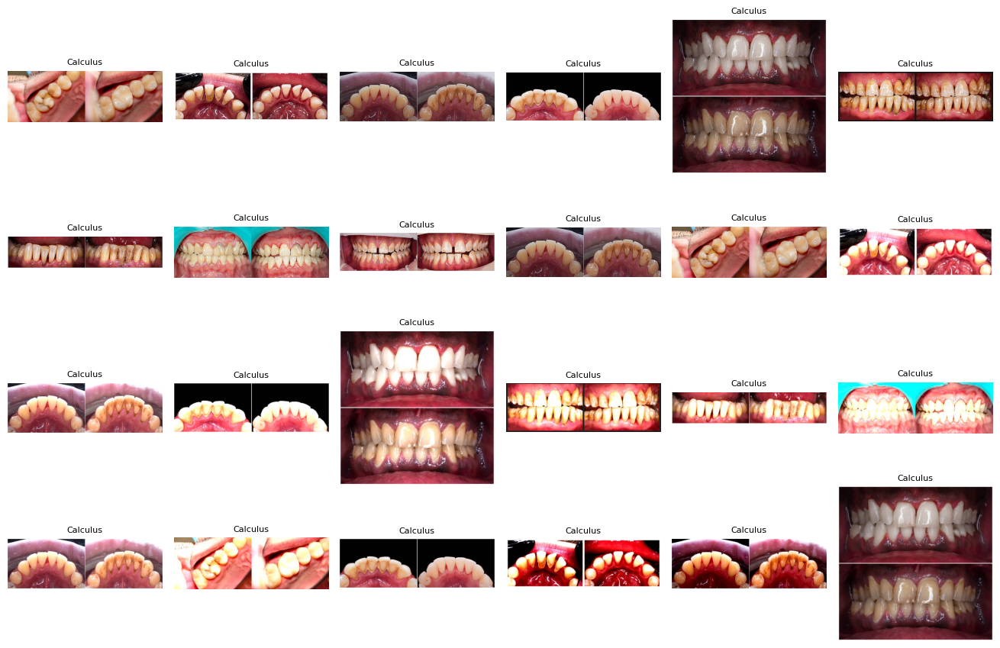

In [12]:
# Contrôle visuel : ce sont bien des images à deux photos collées ? (24 premières)
check = df[df.composite].head(24)
show_images(check.path, [f"{r.label}" for r in check.itertuples()], ncols=6, size=2.2, save="eda_composites_check.png")

✍️ **Images composites (à écrire toi-même)** :
- Les images à fort score sont-elles vraiment des deux photos collées ? Le seuil te semble-t-il bon ?
- Dans quelles classes en trouve-t-on le plus ?
- Que devient l'étiquette d'une image dont une moitié est saine ? (On garde l'étiquette du dataset, on garde et on le note dans les limites, on exclut ?) **Choisis et justifie** — et note-le dans ta question au tuteur si tu hésites.

_(Ton texte ici.)_

Pour les images composites la meilleure méthode est de les repérer manuellement, cela évite de laisser passer des faux négatif et de perdre des images faux positifs.

On en retrouve le plus dans le calculus avec 77 relevé à la main.

Les étiquettes relevés seront supprimé car impropre à l'entrainement.


### 3.5 Tailles et luminosité
Des images de tailles très différentes sont déformées différemment par le redimensionnement. Si une classe est systématiquement plus sombre, le modèle risque d'apprendre la **luminosité** plutôt que la maladie.

Tailles les plus fréquentes :
width  height
612    408       859
275    183       201
612    407       106
       405        97
259    194        72
300    168        65
612    293        51
225    225        46
dtype: int64


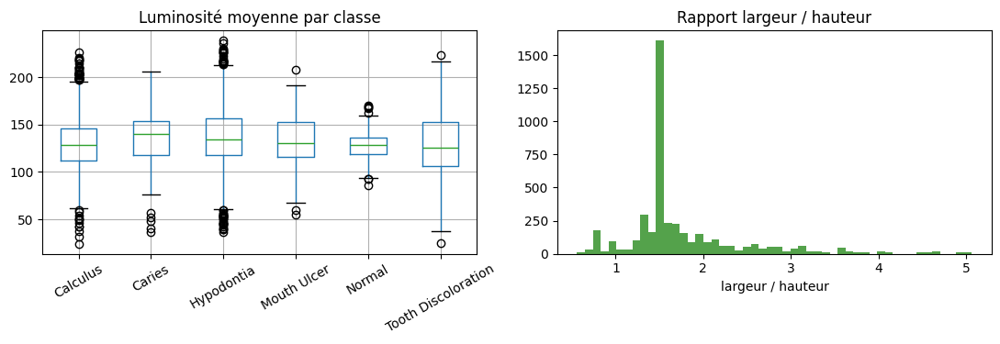

                      width  height  brightness
label                                          
Calculus              611.8   380.7       129.7
Caries                425.2   299.9       135.5
Hypodontia            346.4   184.6       136.4
Mouth Ulcer           321.2   230.9       131.9
Normal               2281.0  2433.1       127.8
Tooth Discoloration   316.2   206.3       128.5


In [13]:
print("Tailles les plus fréquentes :")
print(df.groupby(["width", "height"]).size().sort_values(ascending=False).head(8))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
df.boxplot(column="brightness", by="label", ax=ax[0], rot=30)
ax[0].set_title("Luminosité moyenne par classe"); ax[0].set_xlabel(""); fig.suptitle("")
ax[1].hist(df.width / df.height, bins=50, color="#54A24B"); ax[1].set_title("Rapport largeur / hauteur"); ax[1].set_xlabel("largeur / hauteur")
fig.tight_layout(); fig.savefig(OUT_DIR / "eda_size_brightness.png", dpi=150); plt.show()
print(df.groupby("label")[["width", "height", "brightness"]].mean().round(1))

### 3.5b Une classe vient-elle d'une autre source ? (biais de résolution)
Le tableau ci-dessus montre que les images **Normal** sont environ **6 fois plus grandes** que celles des autres classes. Elles semblent venir d'une autre source (photos de téléphone en haute définition).

**Pourquoi c'est un risque :** même après redimensionnement en 224×224, la netteté et la compression restent différentes. Le modèle pourrait apprendre « photo haute définition = Normal » au lieu de regarder les dents. Pour un vrai patient qui photographie sa bouche avec son téléphone, cela donnerait un faux « Normal ». C'est une **hypothèse** : à vérifier plus tard avec Grad-CAM, et à citer dans les limites du rapport.

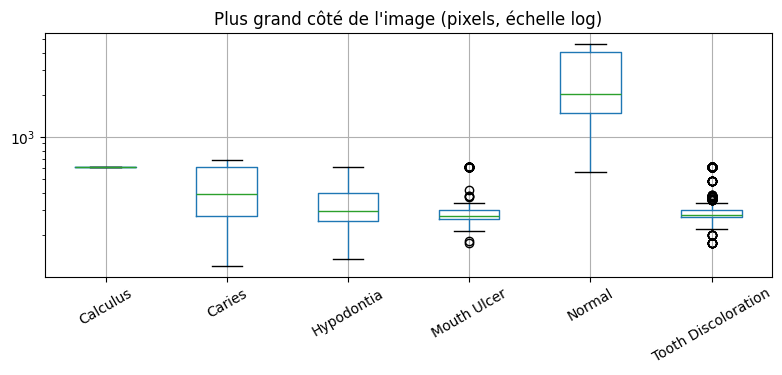

Part des images dont le plus grand côté dépasse 1000 pixels (%) :
label
Calculus                0.0
Caries                  0.0
Hypodontia              0.0
Mouth Ulcer             0.0
Normal                 95.8
Tooth Discoloration     0.0


In [14]:
df["max_side"] = df[["width", "height"]].max(axis=1)
big = (df.max_side > 1000).groupby(df.label).mean().mul(100).round(1)

fig, ax = plt.subplots(figsize=(8, 4))
df.boxplot(column="max_side", by="label", ax=ax, rot=30)
ax.set_yscale("log"); ax.set_title("Plus grand côté de l'image (pixels, échelle log)"); ax.set_xlabel(""); fig.suptitle("")
fig.tight_layout(); fig.savefig(OUT_DIR / "eda_resolution_bias.png", dpi=150); plt.show()

print("Part des images dont le plus grand côté dépasse 1000 pixels (%) :")
print(big.to_string())

### 3.6 Copies modifiées de la même photo (le point critique)
**D'abord on nettoie :**
- on retire les images **identiques avec des étiquettes différentes** (étiquette contradictoire : on ne peut pas lui faire confiance) ;
- on retire les **images composites** (décision de l'équipe en 3.4b : une moitié saine, une moitié malade, l'étiquette est impropre à l'entraînement) ;
- on retire les doublons **exacts** (même fichier), en gardant un exemplaire.

**Ensuite on cherche les copies modifiées (tournées, éclaircies, recadrées) avec des *embeddings*.** Un réseau ResNet50 pré-entraîné sur ImageNet (**rien n'est entraîné ici, aucune étiquette n'est utilisée**) transforme chaque image en 2048 nombres qui décrivent **ce qu'elle représente**. Deux variantes d'une même photo donnent presque les mêmes nombres. On compare deux images avec la **similarité cosinus** (1 = identique, 0 = sans rapport) ; on travaille ici avec la **distance cosinus = 1 − similarité** (0 = identique). On lit aussi chaque image **retournée en miroir** pour attraper les retournements horizontaux.

**Comment vérifier le seuil** (`DUP_THRESHOLD`) : l'histogramme de la distance au voisin le plus proche doit montrer **deux bosses** (copies à gauche, images vraiment différentes à droite). La table de sensibilité montre ensuite ce que change le seuil : un seuil plus haut regroupe plus de copies (moins de fuite) mais crée de très gros groupes (jeux moins équilibrés). **Regarde les groupes et les paires proches du seuil pour confirmer.**

In [15]:
# 1) Étiquettes contradictoires : même fichier, classes différentes -> on retire toutes ces images
n_labels_per_md5 = df.groupby("md5").label.nunique()
conflict_md5 = set(n_labels_per_md5[n_labels_per_md5 > 1].index)
n_conflict_imgs = int(df.md5.isin(conflict_md5).sum())

# 2) Composites (3.4b) -> on retire toutes leurs copies
composite_md5 = set(manual.md5)
n_composite_imgs = int((df.md5.isin(composite_md5) & ~df.md5.isin(conflict_md5)).sum())

# 3) Doublons exacts : on garde le premier exemplaire
removed_md5 = conflict_md5 | composite_md5
keep = ~df.md5.isin(removed_md5) & ~df.md5.duplicated(keep="first")
n_exact = int((df.md5.duplicated(keep="first") & ~df.md5.isin(removed_md5)).sum())

print(f"Images à étiquette contradictoire retirées : {n_conflict_imgs}")
print(f"Images composites retirées                 : {n_composite_imgs}")
print(f"Doublons exacts retirés                    : {n_exact}")

df = df[keep.values].reset_index(drop=True)
print(f"Images restantes : {len(df)}")

Images à étiquette contradictoire retirées : 121
Images composites retirées                 : 93
Doublons exacts retirés                    : 451
Images restantes : 3710


In [16]:
# Embeddings ResNet50 (ImageNet) : 2048 nombres par image, normalisés (longueur 1) pour que le produit scalaire = similarité cosinus
WEIGHTS = models.ResNet50_Weights.IMAGENET1K_V2
resnet = models.resnet50(weights=WEIGHTS)
resnet.fc = torch.nn.Identity()                       # on enlève la couche de classes : on garde les 2048 nombres
resnet = resnet.to(DEVICE).eval()
prep = WEIGHTS.transforms()


class ImgDS(torch.utils.data.Dataset):
    def __init__(self, paths): self.paths = list(paths)
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        with Image.open(self.paths[i]) as im:
            return prep(ImageOps.exif_transpose(im).convert("RGB"))


loader = torch.utils.data.DataLoader(ImgDS(df.path), batch_size=64, shuffle=False, num_workers=2)
E, EF = [], []
with torch.inference_mode():
    for batch in tqdm(loader, desc="embeddings"):
        batch = batch.to(DEVICE)
        E.append(torch.nn.functional.normalize(resnet(batch), dim=1).cpu())
        EF.append(torch.nn.functional.normalize(resnet(torch.flip(batch, dims=[3])), dim=1).cpu())   # version miroir
E, EF = torch.cat(E).numpy(), torch.cat(EF).numpy()
print("Embeddings :", E.shape)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 140MB/s]


embeddings:   0%|          | 0/58 [00:00<?, ?it/s]

Embeddings : (3710, 2048)


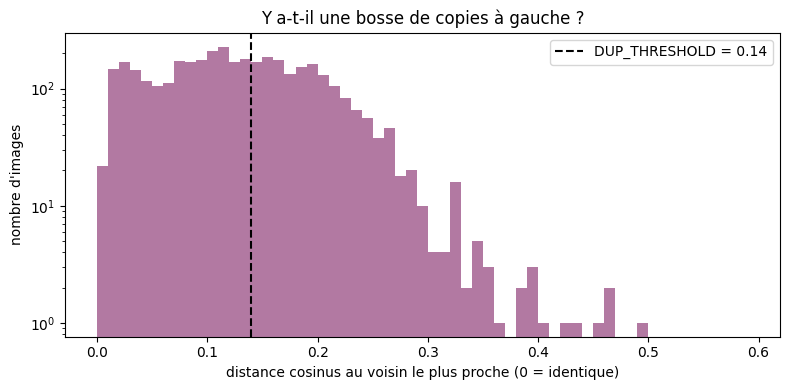

Images dont le voisin le plus proche est à moins de 0.14 : 2113 sur 3710


In [17]:
# Distance cosinus entre toutes les paires = 1 − similarité ; on garde la plus petite entre (image, image) et (image, miroir)
S = np.maximum(E @ E.T, E @ EF.T)
S = np.maximum(S, S.T)
D = 1.0 - S
np.fill_diagonal(D, np.inf)
nn_dist = D.min(axis=1)                            # distance au voisin le plus proche de chaque image

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(nn_dist, bins=np.arange(0, 0.6, 0.01), color="#B279A2")
ax.axvline(DUP_THRESHOLD, color="k", ls="--", label=f"DUP_THRESHOLD = {DUP_THRESHOLD}")
ax.set_yscale("log"); ax.set_xlabel("distance cosinus au voisin le plus proche (0 = identique)"); ax.set_ylabel("nombre d'images")
ax.set_title("Y a-t-il une bosse de copies à gauche ?"); ax.legend()
fig.tight_layout(); fig.savefig(OUT_DIR / "eda_near_duplicates_hist.png", dpi=150); plt.show()

print(f"Images dont le voisin le plus proche est à moins de {DUP_THRESHOLD} : "
      f"{int((nn_dist <= DUP_THRESHOLD).sum())} sur {len(df)}")

✋ **Règle `DUP_THRESHOLD` maintenant** : regarde l'histogramme, puis la **table de sensibilité** juste en dessous. On cherche un seuil qui regroupe les copies **avant** que le plus gros groupe n'explose. Modifie `DUP_THRESHOLD` en haut du notebook si besoin, **relance depuis la section 3.6**, puis regarde si les groupes trouvés sont bien « la même photo modifiée ».

In [18]:
# Sensibilité au seuil : à quel point le nombre de groupes dépend-il du seuil ?
# Lecture : on cherche un PALIER (le nombre de groupes bouge peu) AVANT que le plus gros groupe n'explose
# (un plus gros groupe qui bondit = des images différentes se retrouvent reliées en chaîne : seuil trop haut).
rows = []
for t in [0.10, 0.12, 0.13, 0.14, 0.15, 0.16]:
    n_g, g_id = connected_components(csr_matrix(D <= t), directed=False)
    sz = np.bincount(g_id)
    rows.append({"seuil": t, "groupes": n_g, "plus gros groupe": int(sz.max()),
                 "% images dans un groupe >= 2": round(100 * (sz[g_id] >= 2).mean(), 1)})
sensitivity = pd.DataFrame(rows)
print(sensitivity.to_string(index=False))

 seuil  groupes  plus gros groupe  % images dans un groupe >= 2
  0.10     2771                14                          35.9
  0.12     2394                39                          47.6
  0.13     2221                84                          52.1
  0.14     2048               221                          57.0
  0.15     1868               366                          61.5
  0.16     1675               528                          66.5


In [19]:
# Groupes de copies : deux images sont reliées si leur distance <= seuil ; un groupe = ensemble d'images reliées
n_groups, group_id = connected_components(csr_matrix(D <= DUP_THRESHOLD), directed=False)
df["group_id"] = group_id
sizes = df.group_id.value_counts()
df["mixed_group"] = df.groupby("group_id").label.transform("nunique") > 1

print(f"{len(df)} images -> {n_groups} groupes (≈ nombre de photos originales indépendantes)")
print(f"Images appartenant à un groupe de 2 images ou plus : {int((df.group_id.map(sizes) >= 2).sum())} "
      f"({(df.group_id.map(sizes) >= 2).mean():.0%})")
print("Taille du plus gros groupe :", int(sizes.max()))
print(pd.cut(sizes, [0, 1, 2, 5, 10, 10_000], labels=["1", "2", "3-5", "6-10", ">10"]).value_counts().sort_index().rename("nb de groupes par taille"))

label_conflict = df.groupby("group_id").label.nunique()
print(f"Groupes contenant plusieurs classes différentes : {int((label_conflict > 1).sum())} ({int(df.mixed_group.sum())} images) : gardés entiers dans un seul jeu")

3710 images -> 2048 groupes (≈ nombre de photos originales indépendantes)
Images appartenant à un groupe de 2 images ou plus : 2113 (57%)
Taille du plus gros groupe : 221
count
1       1597
2        199
3-5      139
6-10     100
>10       13
Name: nb de groupes par taille, dtype: int64
Groupes contenant plusieurs classes différentes : 10 (387 images) : gardés entiers dans un seul jeu


Groupe 1 : 221 images


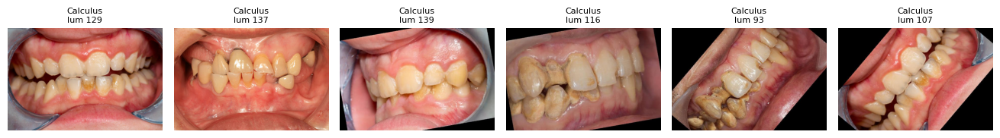

Groupe 275 : 47 images


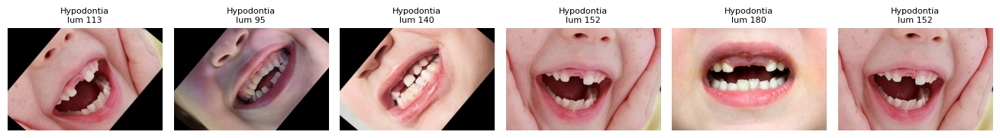

Groupe 1413 : 24 images


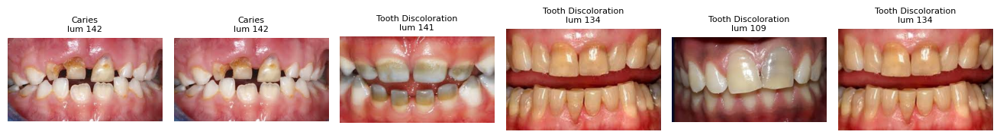

Paires proches du seuil (gauche/droite) :


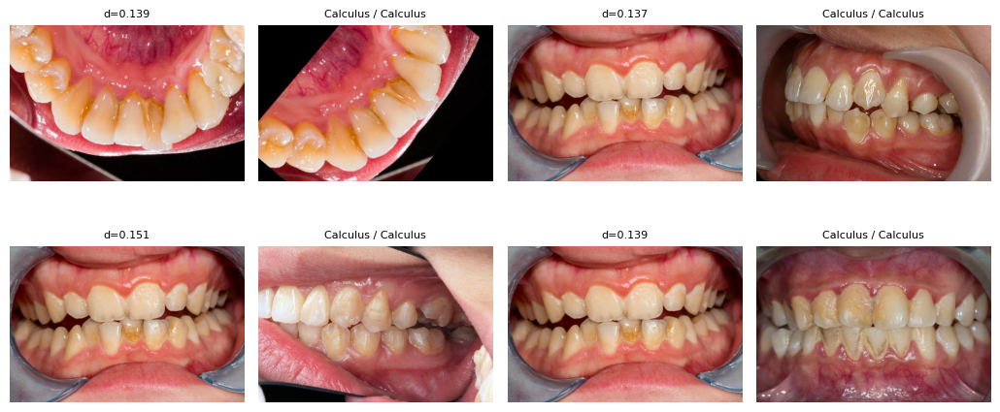

In [20]:
# Regarder les 3 plus gros groupes (6 images max chacun) : sont-ce bien des copies de la même photo ?
for gid in sizes.head(3).index:
    g = df[df.group_id == gid].head(6)
    print(f"Groupe {gid} : {sizes[gid]} images")
    show_images(g.path, [f"{r.label}\nlum {r.brightness:.0f}" for r in g.itertuples()], ncols=6, size=2.2)

# Paires proches du seuil : c'est là que l'on se trompe le plus, donc là qu'il faut regarder
border = np.argwhere(np.triu((D > DUP_THRESHOLD - 0.015) & (D <= DUP_THRESHOLD + 0.015)))[:4]
if len(border):
    print("Paires proches du seuil (gauche/droite) :")
    paths, titles = [], []
    for i, j in border:
        paths += [df.path[i], df.path[j]]; titles += [f"d={D[i, j]:.3f}", f"{df.label[i]} / {df.label[j]}"]
    show_images(paths, titles, ncols=4, size=2.6)

✍️ **Copies modifiées (à écrire toi-même, c'est la découverte clé de l'EDA)** :
- Y a-t-il une bosse à gauche dans l'histogramme ? Quel seuil as-tu choisi et comment l'as-tu justifié ?
- Les groupes affichés sont-ils bien des copies de la même photo ? Des paires proches du seuil te font-elles douter ?
- **Combien de photos indépendantes** reste-t-il (nombre de groupes) par rapport aux images ? Par classe ? (tableau ci-dessous)
- Que ce soit pour le modèle (risque de fuite) ou pour la taille réelle du dataset, qu'est-ce que cela change ?

_(Ton texte ici.)_

In [21]:
indep = pd.DataFrame({
    "images": df.groupby("label").size(),
    "groupes (≈ photos indépendantes)": df.groupby("label").group_id.nunique(),
})
indep["images par groupe"] = (indep.images / indep["groupes (≈ photos indépendantes)"]).round(1)
indep

,images,groupes (≈ photos indépendantes),images par groupe
label,,,
Calculus,732,180,4.1
Caries,194,175,1.1
Hypodontia,1224,653,1.9
Mouth Ulcer,240,203,1.2
Normal,284,266,1.1
Tooth Discoloration,1036,582,1.8


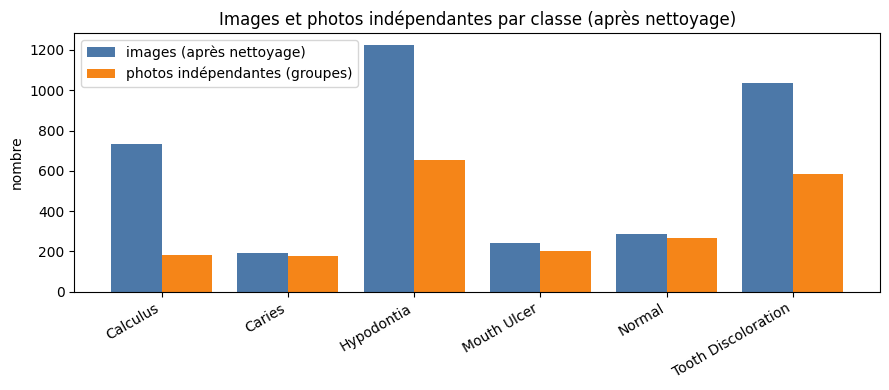

In [22]:
# Le vrai déséquilibre : images après nettoyage, comparées aux photos indépendantes (groupes)
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(indep))
ax.bar(x - 0.2, indep["images"], 0.4, label="images (après nettoyage)", color="#4C78A8")
ax.bar(x + 0.2, indep["groupes (≈ photos indépendantes)"], 0.4, label="photos indépendantes (groupes)", color="#F58518")
ax.set_xticks(x); ax.set_xticklabels(indep.index, rotation=30, ha="right")
ax.set_ylabel("nombre"); ax.set_title("Images et photos indépendantes par classe (après nettoyage)"); ax.legend()
fig.tight_layout(); fig.savefig(OUT_DIR / "eda_independent_photos.png", dpi=150); plt.show()

## 4. Découpage train / validation / test **par groupes**

| Jeu | Rôle |
|---|---|
| **Train** (~70 %) | le modèle apprend dessus |
| **Validation** (~15 %) | on choisit dessus (learning rate, meilleur modèle) |
| **Test** (~15 %) | note finale, **utilisé une seule fois** |

**Par groupes** : toutes les copies d'une même photo vont dans **le même jeu**. C'est ce qui supprime la fuite. **Stratifié** : chaque jeu garde à peu près les mêmes proportions de classes. Les proportions obtenues sont approchées (on déplace des groupes entiers, pas des images isolées).

In [23]:
classes = sorted(df.label.unique())
class_to_idx = {c: i for i, c in enumerate(classes)}
df["y"] = df.label.map(class_to_idx)

# 1) on met de côté le test (~1/7 des groupes), 2) dans le reste on met de côté la validation (~1/6)
n_test_folds = round(1 / TEST_FRACTION)
sg1 = StratifiedGroupKFold(n_splits=n_test_folds, shuffle=True, random_state=SEED)
trainval_idx, test_idx = next(sg1.split(df, df.y, df.group_id))

trainval = df.iloc[trainval_idx]
n_val_folds = round(1 / (VAL_FRACTION / (1 - TEST_FRACTION)))
sg2 = StratifiedGroupKFold(n_splits=n_val_folds, shuffle=True, random_state=SEED)
train_i, val_i = next(sg2.split(trainval, trainval.y, trainval.group_id))

df["split"] = "train"
df.loc[trainval.index[val_i], "split"] = "val"
df.loc[df.index[test_idx], "split"] = "test"

# Contrôle clé : aucun groupe n'est partagé entre deux jeux
assert df.groupby("group_id").split.nunique().max() == 1, "Un groupe est coupé entre deux jeux !"
print("OK : aucun groupe de copies n'est partagé entre train, val et test.")

split_img = pd.crosstab(df.label, df.split)[["train", "val", "test"]]
split_img.loc["TOTAL"] = split_img.sum()
print("\nImages par jeu :"); print(split_img)
print("\nProportions :", (df.split.value_counts(normalize=True)[["train", "val", "test"]] * 100).round(1).to_dict(), "(%)")
split_groups = pd.crosstab(df.drop_duplicates("group_id").label, df.drop_duplicates("group_id").split)[["train", "val", "test"]]
print("\nGroupes (photos indépendantes) par jeu :"); print(split_groups)

OK : aucun groupe de copies n'est partagé entre train, val et test.

Images par jeu :
split                train  val  test
label                                
Calculus               593   95    44
Caries                 136   30    28
Hypodontia             907  172   145
Mouth Ulcer            178   33    29
Normal                 215   36    33
Tooth Discoloration    798  118   120
TOTAL                 2827  484   399

Proportions : {'train': 76.2, 'val': 13.0, 'test': 10.8} (%)

Groupes (photos indépendantes) par jeu :
split                train  val  test
label                                
Calculus               130   26    24
Caries                 124   25    23
Hypodontia             474   88    91
Mouth Ulcer            154   26    23
Normal                 200   33    33
Tooth Discoloration    426   74    74


### 4.1 Audit de fuite : les images les plus proches entre test et train
Le découpage par groupes garantit qu'aucune paire sous le seuil n'est partagée entre deux jeux. Mais si le seuil est **trop bas**, une copie qui s'est échappée de son groupe peut se retrouver de l'autre côté. Pour le vérifier, on regarde les paires **test / train les plus proches** : si elles ressemblent à « la même photo », le seuil est trop bas : **remonte `DUP_THRESHOLD` et relance depuis la section 3.6**.

Distance minimale test -> train : 0.141 | validation -> train : 0.140 (seuil de copies : 0.14)
Images de test dont le plus proche voisin de train est à moins de 0.19 : 199 sur 399
Les 4 paires test/train les plus proches (test à gauche, train à droite) :


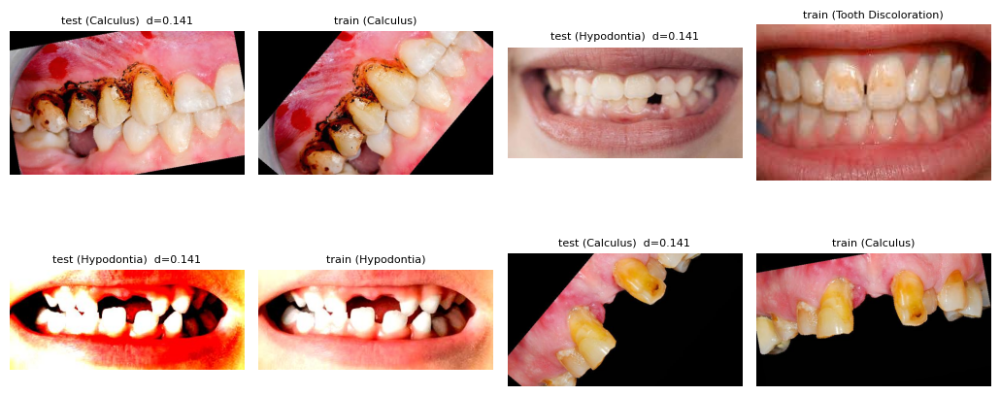

In [24]:
is_tr, is_va, is_te = (df.split == "train").values, (df.split == "val").values, (df.split == "test").values
d_test_train = D[np.ix_(is_te, is_tr)].min(axis=1)       # pour chaque image de test : distance à l'image de train la plus proche
d_val_train = D[np.ix_(is_va, is_tr)].min(axis=1)
print(f"Distance minimale test -> train : {d_test_train.min():.3f} | validation -> train : {d_val_train.min():.3f} (seuil de copies : {DUP_THRESHOLD})")
print(f"Images de test dont le plus proche voisin de train est à moins de {DUP_THRESHOLD + 0.05:.2f} : {int((d_test_train <= DUP_THRESHOLD + 0.05).sum())} sur {is_te.sum()}")

te_pos, tr_pos = np.where(is_te)[0], np.where(is_tr)[0]
closest = np.argsort(d_test_train)[:4]
paths, titles = [], []
for c in closest:
    i = te_pos[c]; j = tr_pos[D[i, tr_pos].argmin()]
    paths += [df.path[i], df.path[j]]; titles += [f"test ({df.label[i]})  d={d_test_train[c]:.3f}", f"train ({df.label[j]})"]
print("Les 4 paires test/train les plus proches (test à gauche, train à droite) :")
show_images(paths, titles, ncols=4, size=2.6)

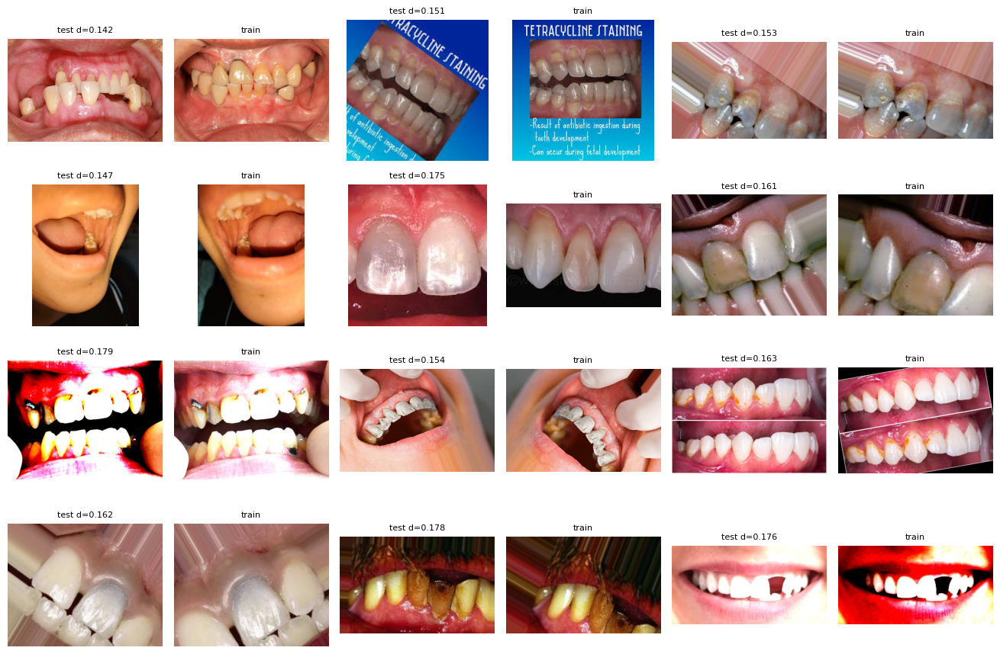

156 images de test sur 399 ont un voisin de train à moins de 0.18


In [25]:
# Estimation de la fuite restante : parmi les images de test qui ont un voisin de train à moins de 0.18,
# combien ont VRAIMENT une copie dans train ? On regarde 12 paires tirées au hasard et on compte.
rng = np.random.default_rng(SEED)
proches = np.where(d_test_train <= 0.18)[0]
pick = rng.choice(proches, size=12, replace=False)
paths, titles = [], []
for c in pick:
    i = te_pos[c]; j = tr_pos[D[i, tr_pos].argmin()]
    paths += [df.path[i], df.path[j]]; titles += [f"test d={d_test_train[c]:.3f}", "train"]
show_images(paths, titles, ncols=6, size=2.2)
print(f"{len(proches)} images de test sur {is_te.sum()} ont un voisin de train à moins de 0.18")

### 4.2 Chiffrer la fuite restante
Regarder les paires ne suffit pas : il faut **un chiffre** pour le rapport. Compte, dans les 12 paires ci-dessus, combien sont **vraiment la même photo** (même patient, même dents, même cadrage), puis écris ce nombre dans `N_VRAIES_COPIES`.

On en déduit une estimation : si 3 paires sur 12 sont de vraies copies, environ 3/12 des images de test « proches » ont encore une copie dans le train.

In [26]:
N_VRAIES_COPIES = None   # ✋ nombre de vraies copies parmi les 12 paires affichées ci-dessus (0 à 12)

if N_VRAIES_COPIES is None:
    print("Remplis N_VRAIES_COPIES après avoir regardé les 12 paires, puis relance cette cellule.")
else:
    part = N_VRAIES_COPIES / len(pick)
    estimation = part * len(proches)
    print(f"{N_VRAIES_COPIES} vraies copies sur {len(pick)} paires regardées.")
    print(f"Estimation : environ {estimation:.0f} images de test sur {is_te.sum()} "
          f"({100 * estimation / is_te.sum():.1f} %) ont encore une copie dans le train.")
    print("Estimation grossière : 12 paires seulement, et les images à plus de 0.18 du train ne sont pas comptées.")

Remplis N_VRAIES_COPIES après avoir regardé les 12 paires, puis relance cette cellule.


✍️ **Découpage (à écrire toi-même)** : les trois jeux ont-ils des proportions de classes proches ? La petite classe (Caries) est-elle présente dans le test en quantité suffisante pour que son score ait un sens ? Que veut dire un test avec très peu de groupes pour une classe ? Les paires test/train les plus proches de l'audit 4.1 sont-elles différentes ?

_(Ton texte ici.)_

## 5. Enregistrer le manifest et la synthèse Excel

Le **manifest** est le fichier qui fait le lien entre le dataset (non versionné) et le code : chemin relatif, classe, groupe, split, empreinte MD5. Il pèse quelques centaines de Ko : on le **commit dans GitHub**. Ton coéquipier n'a qu'à le lire pour avoir **exactement le même split** que toi.

Tout est aussi copié sur Google Drive (`MyDrive/dentalguide/eda_v2/`) : c'est là que le notebook `PR1_notebook_ResNet50` vient le lire.

In [27]:
manifest_cols = ["rel_path", "label", "y", "split", "group_id", "md5", "width", "height", "brightness", "seam", "mixed_group"]
df[manifest_cols].to_csv(MANIFEST_PATH, index=False)
CLASSES_PATH.write_text(json.dumps(classes))
print(f"Manifest enregistré : {MANIFEST_PATH}  ({len(df)} lignes)")
print("Ordre des classes  :", classes)

# Synthèse Excel (utile pour les slides)
summary = {
    "images_par_classe": df.label.value_counts().rename_axis("classe").reset_index(name="images"),
    "photos_independantes": indep.reset_index().rename(columns={"label": "classe"}),
    "split_images": split_img.reset_index().rename(columns={"label": "classe"}),
    "split_groupes": split_groups.reset_index().rename(columns={"label": "classe"}),
    "composites_par_classe": comp.reset_index().rename(columns={"label": "classe"}),
    "nettoyage": pd.DataFrame({
        "etape": ["étiquette contradictoire", "images composites", "doublons exacts", "groupes de copies", "images finales"],
        "valeur": [n_conflict_imgs, n_composite_imgs, n_exact, int(n_groups), len(df)]}),
}
with pd.ExcelWriter(OUT_DIR / "eda_summary.xlsx") as xw:
    for name, t in summary.items():
        t.to_excel(xw, sheet_name=name, index=False)
print("Synthèse Excel :", OUT_DIR / "eda_summary.xlsx")

# Copie durable sur Google Drive (Colab efface /content à la fin de la session)
shutil.copy(MANIFEST_PATH, DRIVE_DIR / "data_manifest.csv")
shutil.copy(CLASSES_PATH, DRIVE_DIR / "class_names.json")
shutil.copytree(OUT_DIR, DRIVE_DIR / "eda", dirs_exist_ok=True)
print("Copié sur Drive :", sorted(p.name for p in DRIVE_DIR.iterdir()))

Manifest enregistré : data/data_manifest.csv  (3710 lignes)
Ordre des classes  : ['Calculus', 'Caries', 'Hypodontia', 'Mouth Ulcer', 'Normal', 'Tooth Discoloration']
Synthèse Excel : outputs/eda/eda_summary.xlsx
Copié sur Drive : ['class_names.json', 'composites_manual.csv', 'data_manifest.csv', 'eda']


## 6. Checklist avant de continuer
- [ ] J'ai regardé des images de **chaque** classe (pas seulement la première)
- [ ] J'ai réglé `DUP_THRESHOLD` en regardant l'histogramme, la table de sensibilité **et** les groupes
- [ ] J'ai vérifié les composites (contrôle visuel en 3.4b)
- [ ] J'ai rempli `N_VRAIES_COPIES` (4.2)
- [ ] Les cellules ✍️ sont écrites avec mes mots
- [ ] Depuis `MyDrive/dentalguide/eda_v2/`, j'ai copié `data_manifest.csv`, `class_names.json` et `composites_manual.csv` dans `data/` du dépôt, puis **commité** (par une seule personne : les autres vérifient qu'ils obtiennent le même fichier)
- [ ] Mon AI Use Log est à jour